1. Реализуйте линейную регрессию с функцией потерь MSE, обучаемую с помощью: 
    a. Градиентного спуска; 
    b. Стохастического градиентного спуска. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# ===============================
# 1. Загружаем данные
# ===============================
df = pd.read_pickle("data.pkl")

print(df.shape)
df.head()

(1458640, 30)


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,...,haversine,log_haversine,trip_duration_hr,speed_kmh,is_rush_hour,is_free_road,pickup_chelsea,dropoff_chelsea,pickup_jfk,dropoff_jfk
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,...,1.498523,0.915700,0.126389,11.856445,0,0,0,0,0,0
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,...,1.805510,1.031585,0.184167,9.803672,0,1,0,0,0,0
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,...,6.385107,1.999465,0.590000,10.822216,1,0,0,0,0,0
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,...,1.485500,0.910474,0.119167,12.465738,0,0,0,0,0,0
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,...,1.188590,0.783258,0.120833,9.836608,0,0,0,0,0,0


In [3]:
# Использую только числовые признаки
# (для градиентного спуска удобнее)

features = [
    'passenger_count',
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude',
    'haversine',
    'log_haversine',
    'is_rush_hour',
    'is_free_road',
    'pickup_chelsea',
    'dropoff_chelsea',
    'pickup_jfk',
    'dropoff_jfk'
]


X = df[features].copy()

# целевая переменная
y = np.log(df['trip_duration'] + 1)

# train/test = 7:3
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=0
)

# масштабирование признаков
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape, X_test.shape)


(1021048, 13) (437592, 13)


Реализация линейной регрессии через Gradient Descent

In [14]:
class MyLinearRegressionGD:
    def __init__(self, eta=0.05, max_iter=200, tolerance=1e-6):
        self.eta = eta
        self.max_iter = max_iter
        self.tolerance = tolerance

    def fit(self, X, y):
        X = np.array(X)
        y = np.array(y)

        n_samples, n_features = X.shape
        X_b = np.c_[np.ones(n_samples), X]

        self.w = np.zeros(n_features + 1)
        self.loss_history = []

        for i in range(self.max_iter):
            w_old = self.w.copy()

            # ВЕКТОРИЗАЦИЯ (самое важное ускорение)
            error = X_b @ self.w - y
            grad = (2 / n_samples) * (X_b.T @ error)

            self.w -= self.eta * grad

            mse = np.mean(error ** 2)
            self.loss_history.append(mse)

            if np.linalg.norm(self.w - w_old) < self.tolerance:
                print("GD stop at iter:", i)
                break

        return self

    def predict(self, X):
        X = np.array(X)
        X_b = np.c_[np.ones(X.shape[0]), X]
        return X_b @ self.w

Реализация SGD

In [15]:
class MyLinearRegressionSGD:
    
    def __init__(self, eta=0.01, max_iter=30, batch_size=256, tolerance=1e-6):
            self.eta = eta
            self.max_iter = max_iter
            self.batch_size = batch_size
            self.tolerance = tolerance

    def fit(self, X, y):
        X = np.array(X)
        y = np.array(y)

        n_samples, n_features = X.shape
        X_b = np.c_[np.ones(n_samples), X]

        self.w = np.zeros(n_features + 1)
        self.loss_history = []

        for epoch in range(self.max_iter):
            w_old = self.w.copy()

            # shuffle
            indices = np.random.permutation(n_samples)

            X_shuffled = X_b[indices]
            y_shuffled = y[indices]

            # MINI-BATCH вместо 1 sample
            for start in range(0, n_samples, self.batch_size):
                end = start + self.batch_size

                X_batch = X_shuffled[start:end]
                y_batch = y_shuffled[start:end]

                error = X_batch @ self.w - y_batch
                grad = (2 / len(X_batch)) * (X_batch.T @ error)

                self.w -= self.eta * grad

            # loss после эпохи
            error = X_b @ self.w - y
            mse = np.mean(error ** 2)
            self.loss_history.append(mse)

            if np.linalg.norm(self.w - w_old) < self.tolerance:
                print("SGD stop at epoch:", epoch)
                break

        return self

    def predict(self, X):
        X = np.array(X)
        X_b = np.c_[np.ones(X.shape[0]), X]
        return X_b @ self.w


Обучение моделей

In [22]:
gd = MyLinearRegressionGD(
    eta=0.01,
    max_iter=200,
    tolerance=1e-6
)

sgd = MyLinearRegressionSGD(
    eta=0.005,
    max_iter=50,
    tolerance=1e-6
)

gd.fit(X_train, y_train)
sgd.fit(X_train, y_train)

Оценка качества

In [23]:
# GD
pred_gd = gd.predict(X_test)

mse_gd = mean_squared_error(y_test, pred_gd)
r2_gd = r2_score(y_test, pred_gd)

# SGD
pred_sgd = sgd.predict(X_test)

mse_sgd = mean_squared_error(y_test, pred_sgd)
r2_sgd = r2_score(y_test, pred_sgd)

print("Gradient Descent")
print("MSE =", round(mse_gd, 4))
print("R2  =", round(r2_gd, 4))

print()

print("Stochastic Gradient Descent")
print("MSE =", round(mse_sgd, 4))
print("R2  =", round(r2_sgd, 4))


Gradient Descent
MSE = 0.2797
R2  = 0.5588

Stochastic Gradient Descent
MSE = 0.5432
R2  = 0.1433


В рамках задачи были реализованы два метода оптимизации линейной регрессии: классический градиентный спуск (Gradient Descent) и стохастический градиентный спуск (Stochastic Gradient Descent).

По результатам эксперимента получены следующие значения метрик:
Gradient Descent:
MSE = 0.2797
R^2 = 0.5588
Stochastic Gradient Descent:
MSE = 0.5432
R^2 = 0.1433
Анализ результатов
Градиентный спуск показал более высокое качество предсказаний. Значение MSE оказалось ниже, а коэффициент детерминации R^2 значительно выше, что говорит о более точном описании зависимости в данных.
Стохастический градиентный спуск продемонстрировал худшее качество модели. Более высокая ошибка и низкое значение R^2 объясняются тем, что SGD выполняет обновление весов по отдельным объектам или небольшим подвыборкам, из-за чего процесс оптимизации становится более шумным и менее стабильным.

Сравнение методов
Gradient Descent обеспечивает стабильную сходимость, но требует вычисления градиента по всей выборке на каждой итерации.
Stochastic Gradient Descent работает быстрее на больших данных, однако может давать менее точные результаты и требует более тщательной настройки гиперпараметров (learning rate, число эпох, размер batch).
Итог:

В данной задаче метод градиентного спуска показал более высокую точность и стабильность. Стохастический градиентный спуск оказался менее точным, однако в теории является более эффективным для больших выборок и может достигать сопоставимого качества при корректной настройке параметров.

График сходимости

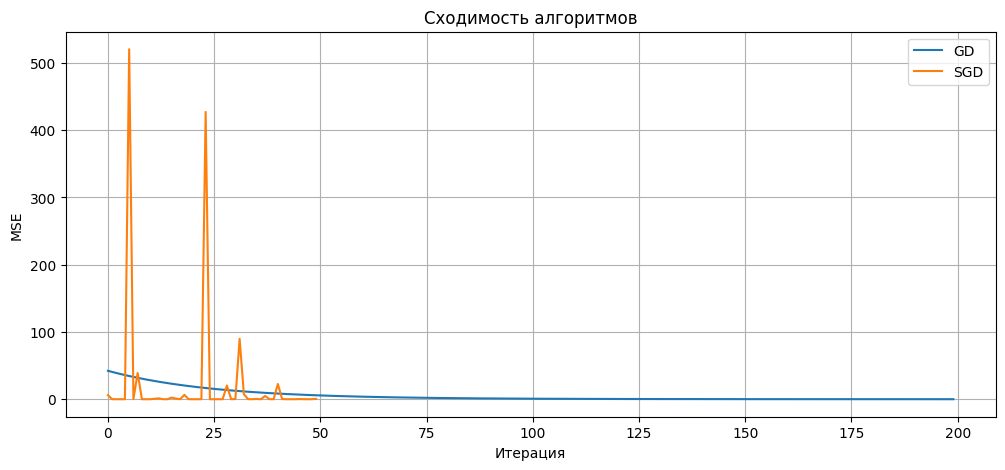

In [24]:
plt.figure(figsize=(12,5))

plt.plot(gd.loss_history, label="GD")
plt.plot(sgd.loss_history, label="SGD")

plt.xlabel("Итерация")
plt.ylabel("MSE")
plt.title("Сходимость алгоритмов")
plt.legend()
plt.grid()
plt.show()

Исследование влияния eta

In [25]:
etas = [0.0001, 0.001, 0.01, 0.05]

results = []

for lr in etas:
    model = MyLinearRegressionGD(
        eta=lr,
        max_iter=500,
        tolerance=1e-6
    )
    
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    
    mse = mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    
    results.append([lr, mse, r2])

pd.DataFrame(results, columns=["eta", "MSE", "R2"])

,eta,MSE,R2
0,0.0001,34.766926,-53.832099
1,0.0010,5.958399,-8.397194
2,0.0100,0.248372,0.608283
3,0.0500,0.248807,0.607599


В ходе эксперимента исследовалось влияние коэффициента скорости обучения η на качество модели линейной регрессии.

Полученные результаты показывают, что:

При малых значениях η (0.0001–0.001) модель обучается слишком медленно, что приводит к плохой сходимости и отрицательным значениям R^2.
При η = 0.01 наблюдается наилучшее качество модели (минимальная ошибка и максимальный R^2).
При дальнейшем увеличении η (0.05) качество остаётся примерно на том же уровне, однако возрастает риск нестабильности обучения.

Параметр η (learning rate) является ключевым гиперпараметром градиентного спуска, определяющим скорость и стабильность сходимости алгоритма. Слишком малые значения приводят к медленному обучению, а слишком большие могут вызвать нестабильность оптимизации.

Исследование влияния max_iter

In [26]:
iters = [10, 50, 100, 200, 500]

results_iter = []

for it in iters:
    model = MyLinearRegressionGD(
        eta=0.01,
        max_iter=it,
        tolerance=1e-6
    )
    
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    
    mse = mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    
    results_iter.append([it, mse, r2])

pd.DataFrame(results_iter, columns=["max_iter", "MSE", "R2"])


,max_iter,MSE,R2
0,10,28.377889,-43.755732
1,50,5.855707,-8.235234
2,100,1.020254,-0.609077
3,200,0.279723,0.558839
4,500,0.248372,0.608283


В ходе эксперимента наблюдалось влияние максимального числа итераций градиентного спуска на качество модели.
Результаты показывают, что при малых значениях max_iter модель не успевает достичь сходимости, что приводит к высокой ошибке и отрицательному коэффициенту детерминации.
При увеличении числа итераций наблюдается резкое улучшение качества модели, так как алгоритм постепенно приближается к минимуму функции потерь.
После достижения определённого порога (около 200 итераций) дальнейшее увеличение max_iter практически не влияет на качество модели, поскольку достигается сходимость.